# Global Solution 2026.2 — Machine Learning & Análise Multivariada (MLAM)
## Desafio CitizenTech: Acessibilidade Habitacional Urbana e Planejamento de Moradia Cidadã

- **Curso:** Bacharelado em Ciência da Computação — Turma `1CCPJ`
- **Integrantes:**
  - **Gustavo de Souza Correa** — RM `570746`
  - **Arthur Tae Gun Yong** — RM `570647`
- **Base de Dados:** *California Housing Prices* (Censo Demográfico e Habitacional dos EUA — 20.640 setores censitários)
- **Fonte Oficial:** Kaggle (`camnugent/california-housing-prices`) — <https://www.kaggle.com/datasets/camnugent/california-housing-prices>

---
### 01) Contextualização CitizenTech, Coleta e Preparação da Base de Dados
O acesso à moradia digna e financeiramente acessível é um dos pilares centrais do **CitizenTech** no planejamento urbano moderno. Compreender como fatores socioeconômicos (como a **Renda Mediana** das famílias) e estruturais dos bairros (**Idade Mediana dos Imóveis** e **Volume Total de Cômodos**) determinam o **Valor Mediano dos Imóveis** permite que gestores públicos e plataformas cívicas identifiquem zonas de pressão imobiliária, gentrificação e déficit habitacional para direcionar subsídios e programas de habitação social.


In [1]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

if os.path.exists("housing_original.csv"):
    arquivo_csv = "housing_original.csv"
else:
    caminho_pasta = kagglehub.dataset_download("camnugent/california-housing-prices")
    arquivo_csv = os.path.join(caminho_pasta, "housing.csv")

df = pd.read_csv(arquivo_csv)

df = df.rename(
    columns={
        "median_income": "Renda_Mediana",
        "housing_median_age": "Idade_Imovel",
        "total_rooms": "Total_Comodos",
        "population": "Populacao_Bairro",
        "median_house_value": "Valor_Imovel",
    }
)

colunas_analise = [
    "Renda_Mediana",
    "Idade_Imovel",
    "Total_Comodos",
    "Populacao_Bairro",
    "Valor_Imovel",
]
df = df[colunas_analise].dropna().copy()

mediana_valor = df["Valor_Imovel"].median()
df["Valor_Alto"] = (df["Valor_Imovel"] > mediana_valor).astype(int)

df.to_csv("housing_kaggle.csv", index=False)
print(f"Dataset carregado e limpo com sucesso! Registros válidos: {len(df)}")
print(f"Mediana de Valor_Imovel (limiar Valor_Alto=1): US$ {mediana_valor:,.2f}")
print("\nResumo Estatístico das Variáveis:")
print(df.describe().round(4))


Dataset carregado e limpo com sucesso! Registros válidos: 20640
Mediana de Valor_Imovel (limiar Valor_Alto=1): US$ 179,700.00

Resumo Estatístico das Variáveis:
       Renda_Mediana  Idade_Imovel  Total_Comodos  Populacao_Bairro  Valor_Imovel  Valor_Alto
count     20640.0000    20640.0000     20640.0000        20640.0000    20640.0000  20640.0000
mean          3.8707       28.6395      2635.7631         1425.4767   206855.8169      0.4999
std           1.8998       12.5856      2181.6153         1132.4621   115395.6159      0.5000
min           0.4999        1.0000         2.0000            3.0000    14999.0000      0.0000
25%           2.5634       18.0000      1447.7500          787.0000   119600.0000      0.0000
50%           3.5348       29.0000      2127.0000         1166.0000   179700.0000      0.0000
75%           4.7432       37.0000      3148.0000         1725.0000   264725.0000      1.0000
max          15.0001       52.0000     39320.0000        35682.0000   500001.0000      

---
### 02) Distribuição Normal de Probabilidade (`Renda_Mediana`)
Assumindo que a variável `Renda_Mediana` ($X$, expressa em dezenas de milhares de dólares) segue uma Distribuição Normal $X \sim N(\mu, \sigma^2)$ com média $\mu = 3,8707$ e desvio padrão populacional $\sigma = 1,8998$:
- **a)** $P(X < \mu) = P(Z < 0) = 0,5000$ ($50,00\%$) $\rightarrow$ **Evento Equiprovável (50%)**, devido à simetria perfeita da distribuição normal em torno da média.
- **b)** $P(X > Md) = P(X > 3,5348) = P(Z > -0,1768) = 0,5702$ ($57,02\%$) $\rightarrow$ **Evento Provável (Moderadamente Provável)**, refletindo a assimetria positiva da renda real ($\mu > Md$).


Média: 3.8707 | Mediana: 3.5348 | Desvio Padrão: 1.8998
a) P(X < Média) = 0.5000 (50.00%) -> Evento Equiprovável (50%)
b) P(X > Mediana) = 0.5702 (57.02%) -> Evento Provável


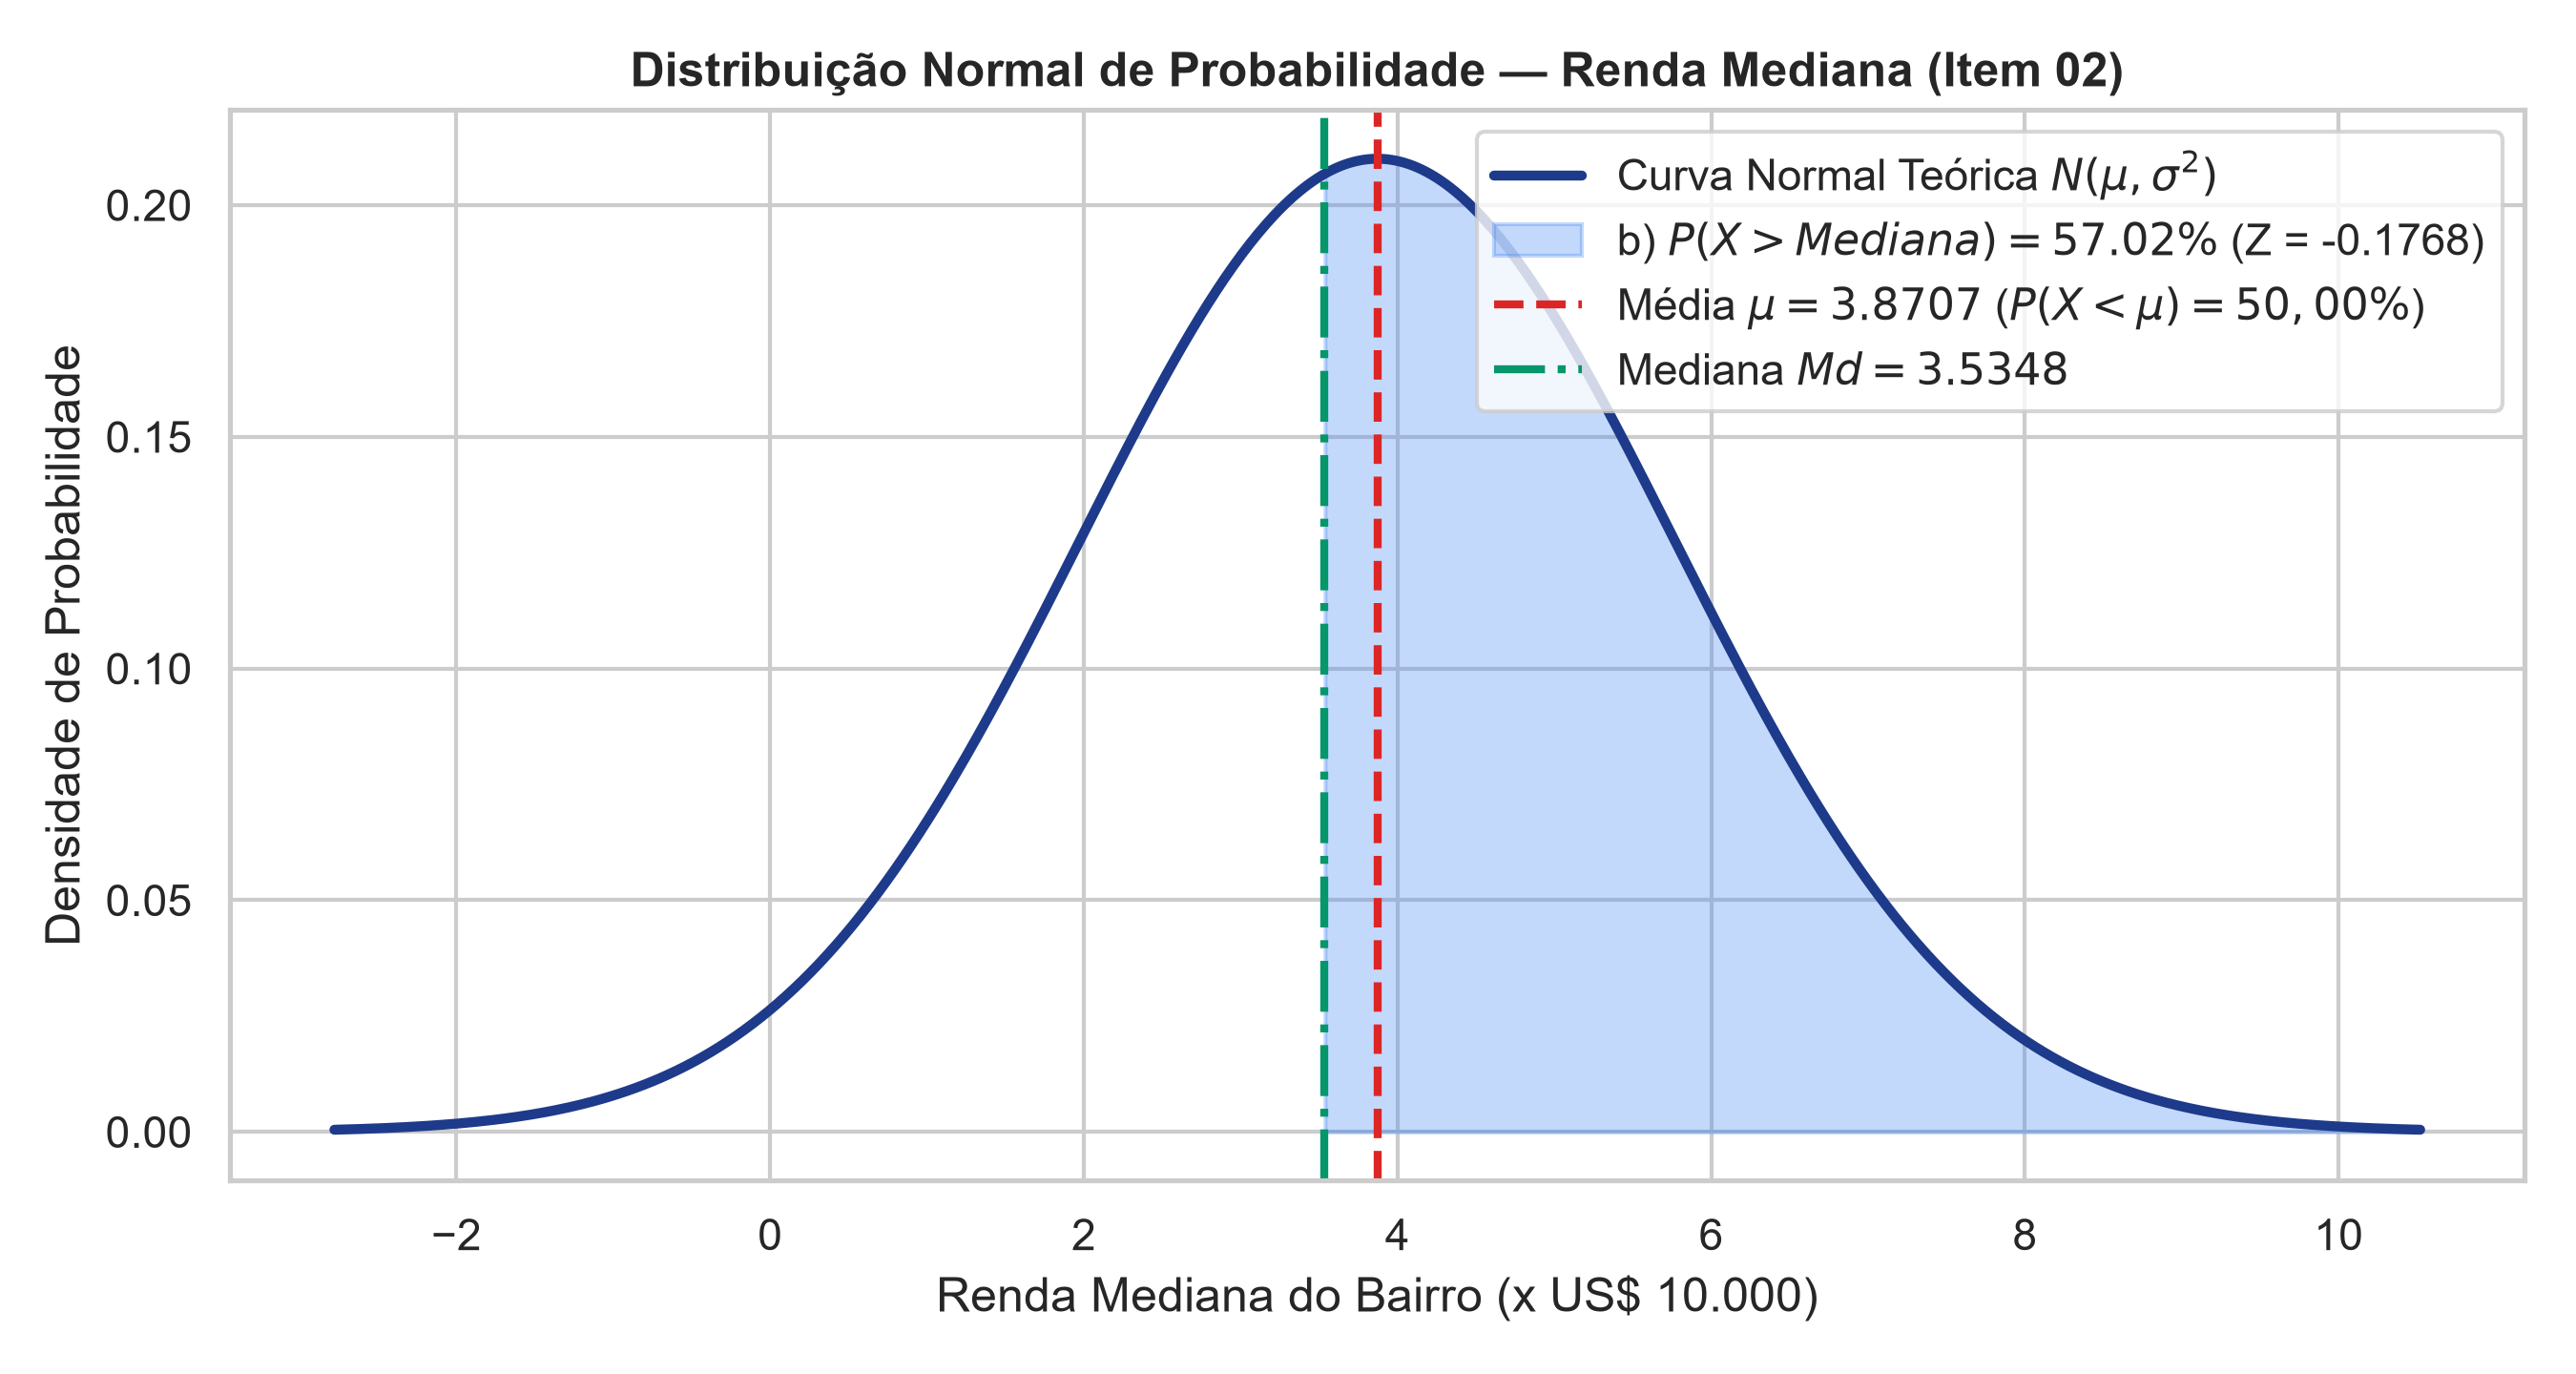

In [2]:
var_renda = df["Renda_Mediana"]
media = var_renda.mean()
mediana = var_renda.median()
dp = var_renda.std(ddof=0)

prob_a = stats.norm.cdf(media, loc=media, scale=dp)
prob_b = 1 - stats.norm.cdf(mediana, loc=media, scale=dp)

def classificar(p):
    if np.isclose(p, 0.50, atol=1e-4):
        return "Evento Equiprovável (50%)"
    elif p < 0.25:
        return "Evento Improvável"
    elif p < 0.50:
        return "Evento Moderadamente Improvável"
    elif p < 0.75:
        return "Evento Provável"
    else:
        return "Evento Muito Provável"

print(f"Média: {media:.4f} | Mediana: {mediana:.4f} | Desvio Padrão: {dp:.4f}")
print(f"a) P(X < Média) = {prob_a:.4f} ({prob_a*100:.2f}%) -> {classificar(prob_a)}")
print(f"b) P(X > Mediana) = {prob_b:.4f} ({prob_b*100:.2f}%) -> {classificar(prob_b)}")


---
### 03) Testes de Hipóteses para a Média (Teste Z — `Renda_Mediana`)
Com $\mu_0 = 3,8707$ e $\sigma = 1,8998$ conhecidos da população:
- **a) Teste Unilateral à Esquerda ($n = 20$, $\alpha = 6\%$):** $H_0: \mu = 3,8707$ vs $H_1: \mu < 3,8707$. Obteve-se $\bar{x} = 3,9271$, $Z_{calc} = 0,1328 > Z_{crit} = -1,5548$ ($p\text{-valor} = 0,5528 \ge 0,06$). **Não se rejeita $H_0$**.
- **b) Teste Unilateral à Direita ($n = 25$, $\alpha = 9\%$):** $H_0: \mu = 3,8707$ vs $H_1: \mu > 3,8707$. Obteve-se $\bar{x} = 3,7607$, $Z_{calc} = -0,2893 \le Z_{crit} = +1,3408$ ($p\text{-valor} = 0,6138 \ge 0,09$). **Não se rejeita $H_0$**.


a) Teste Unilateral à Esquerda (n=20, alpha=6%): x_barra = 3.9271 | Z_calc = 0.1328 | Z_crit = -1.5548 | p-valor = 0.5528
   Conclusão: Não rejeita H0
b) Teste Unilateral à Direita (n=25, alpha=9%): x_barra = 3.7607 | Z_calc = -0.2893 | Z_crit = 1.3408 | p-valor = 0.6138
   Conclusão: Não rejeita H0


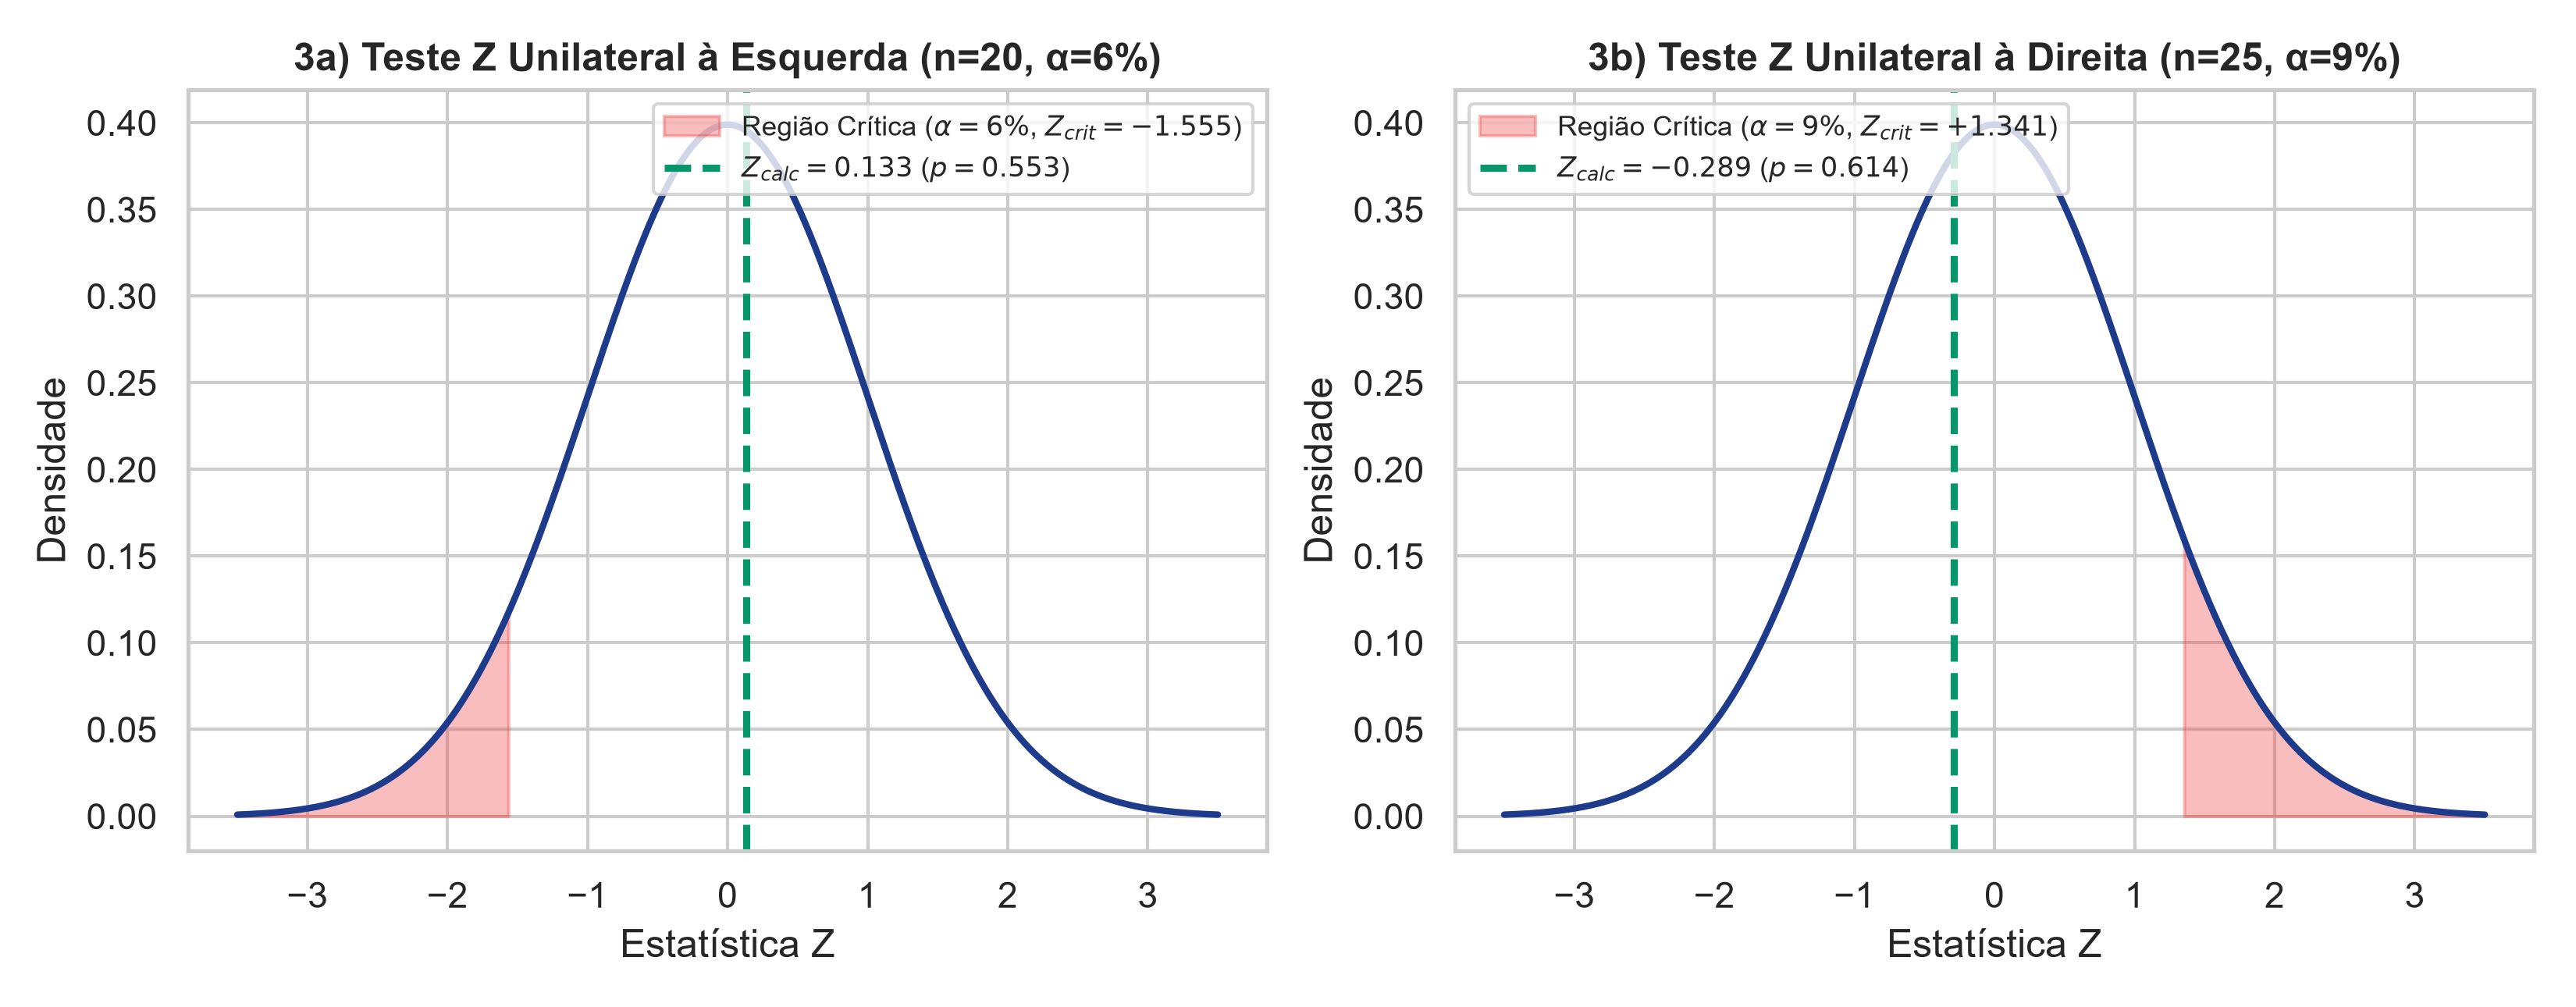

In [3]:
amostra_a = var_renda.sample(n=20, random_state=42)
z_calc_a = (amostra_a.mean() - media) / (dp / np.sqrt(20))
z_crit_a = stats.norm.ppf(0.06)
p_valor_a = stats.norm.cdf(z_calc_a)

print(f"a) Teste Unilateral à Esquerda (n=20, alpha=6%): x_barra = {amostra_a.mean():.4f} | Z_calc = {z_calc_a:.4f} | Z_crit = {z_crit_a:.4f} | p-valor = {p_valor_a:.4f}")
print("   Conclusão:", "Rejeita H0" if p_valor_a < 0.06 else "Não rejeita H0")

amostra_b = var_renda.sample(n=25, random_state=99)
z_calc_b = (amostra_b.mean() - media) / (dp / np.sqrt(25))
z_crit_b = stats.norm.ppf(1 - 0.09)
p_valor_b = 1 - stats.norm.cdf(z_calc_b)

print(f"b) Teste Unilateral à Direita (n=25, alpha=9%): x_barra = {amostra_b.mean():.4f} | Z_calc = {z_calc_b:.4f} | Z_crit = {z_crit_b:.4f} | p-valor = {p_valor_b:.4f}")
print("   Conclusão:", "Rejeita H0" if p_valor_b < 0.09 else "Não rejeita H0")


---
### 04) Análise Bivariada e Regressão Linear Simples (`Renda_Mediana` vs `Valor_Imovel`)
Investigação da relação linear entre a capacidade financeira das famílias (`Renda_Mediana`) e o preço mediano das moradias (`Valor_Imovel`).


b) Covariância: 150,847.4828
b) Correlação de Pearson (r): 0.6881 (p-valor: 0.0000e+00)
d) Equação: Valor_Imovel = 45085.5767 + (41793.8492 * Renda_Mediana)
e) R²: 0.4734 | Teste F: 18556.5716 (p-valor F: 0.0000e+00)
f) Previsão para Renda_Mediana = 5.0 ($50k) -> Valor estimado = $ 254,054.82


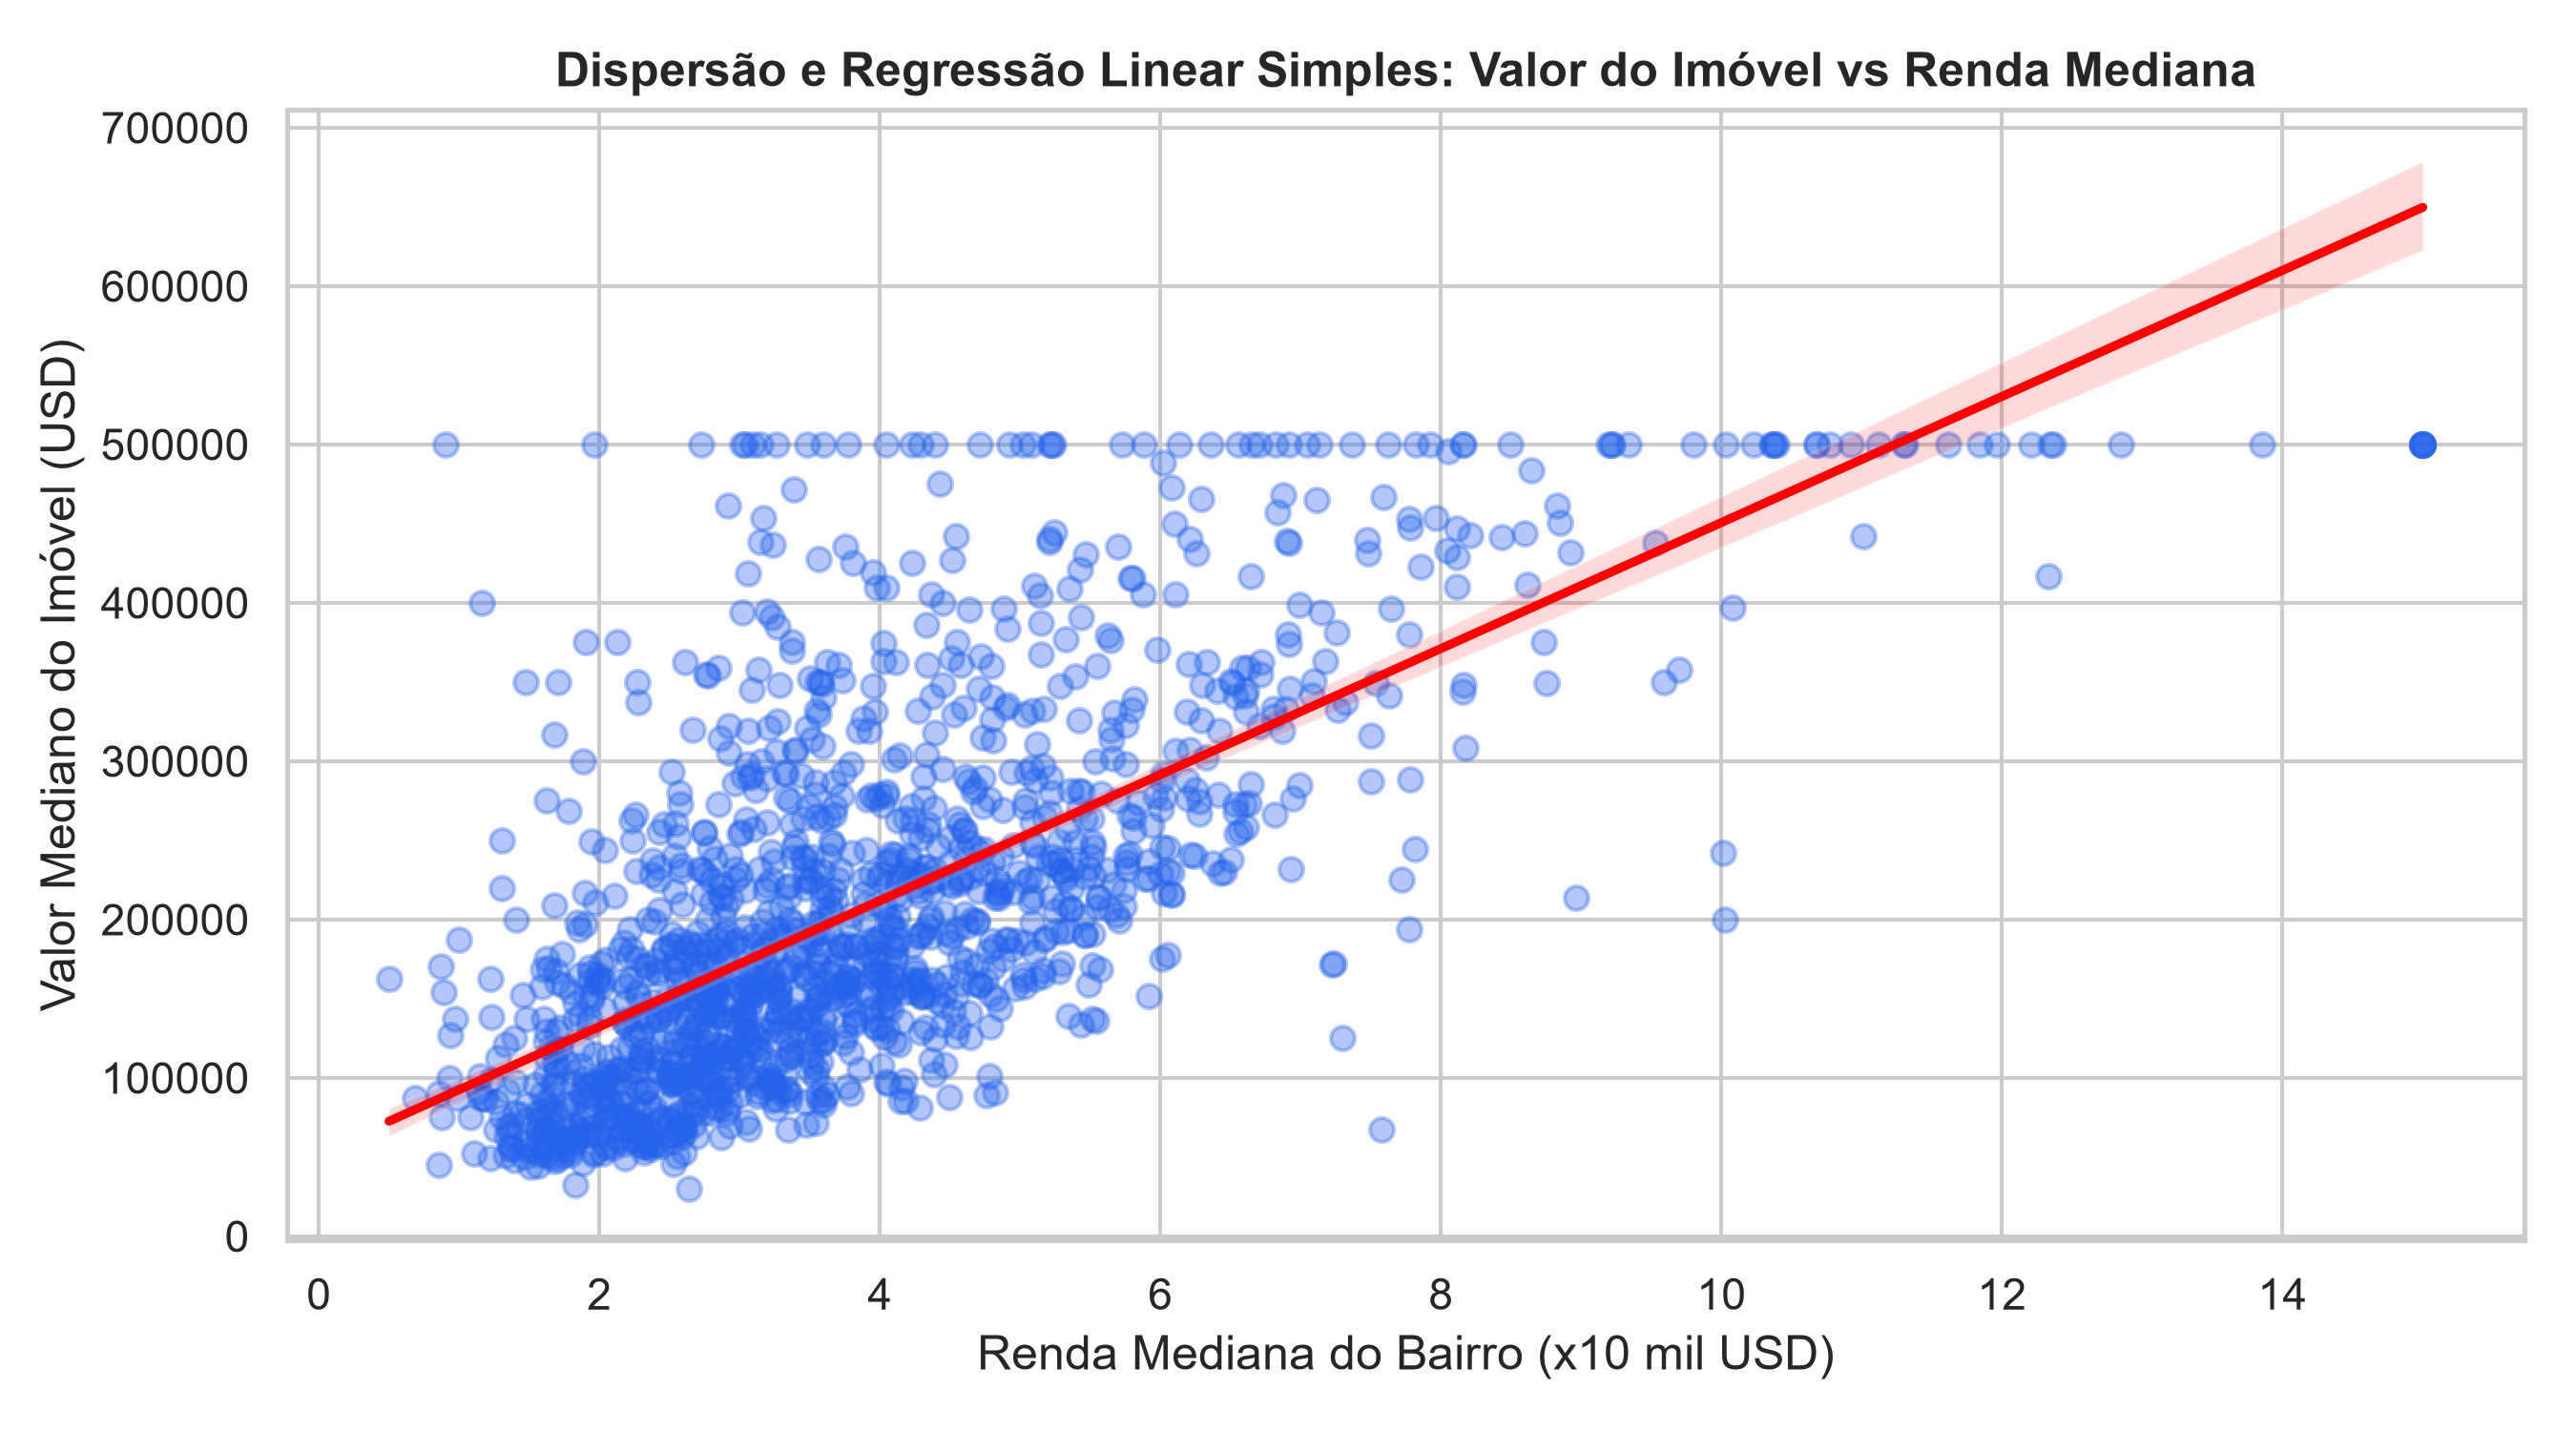

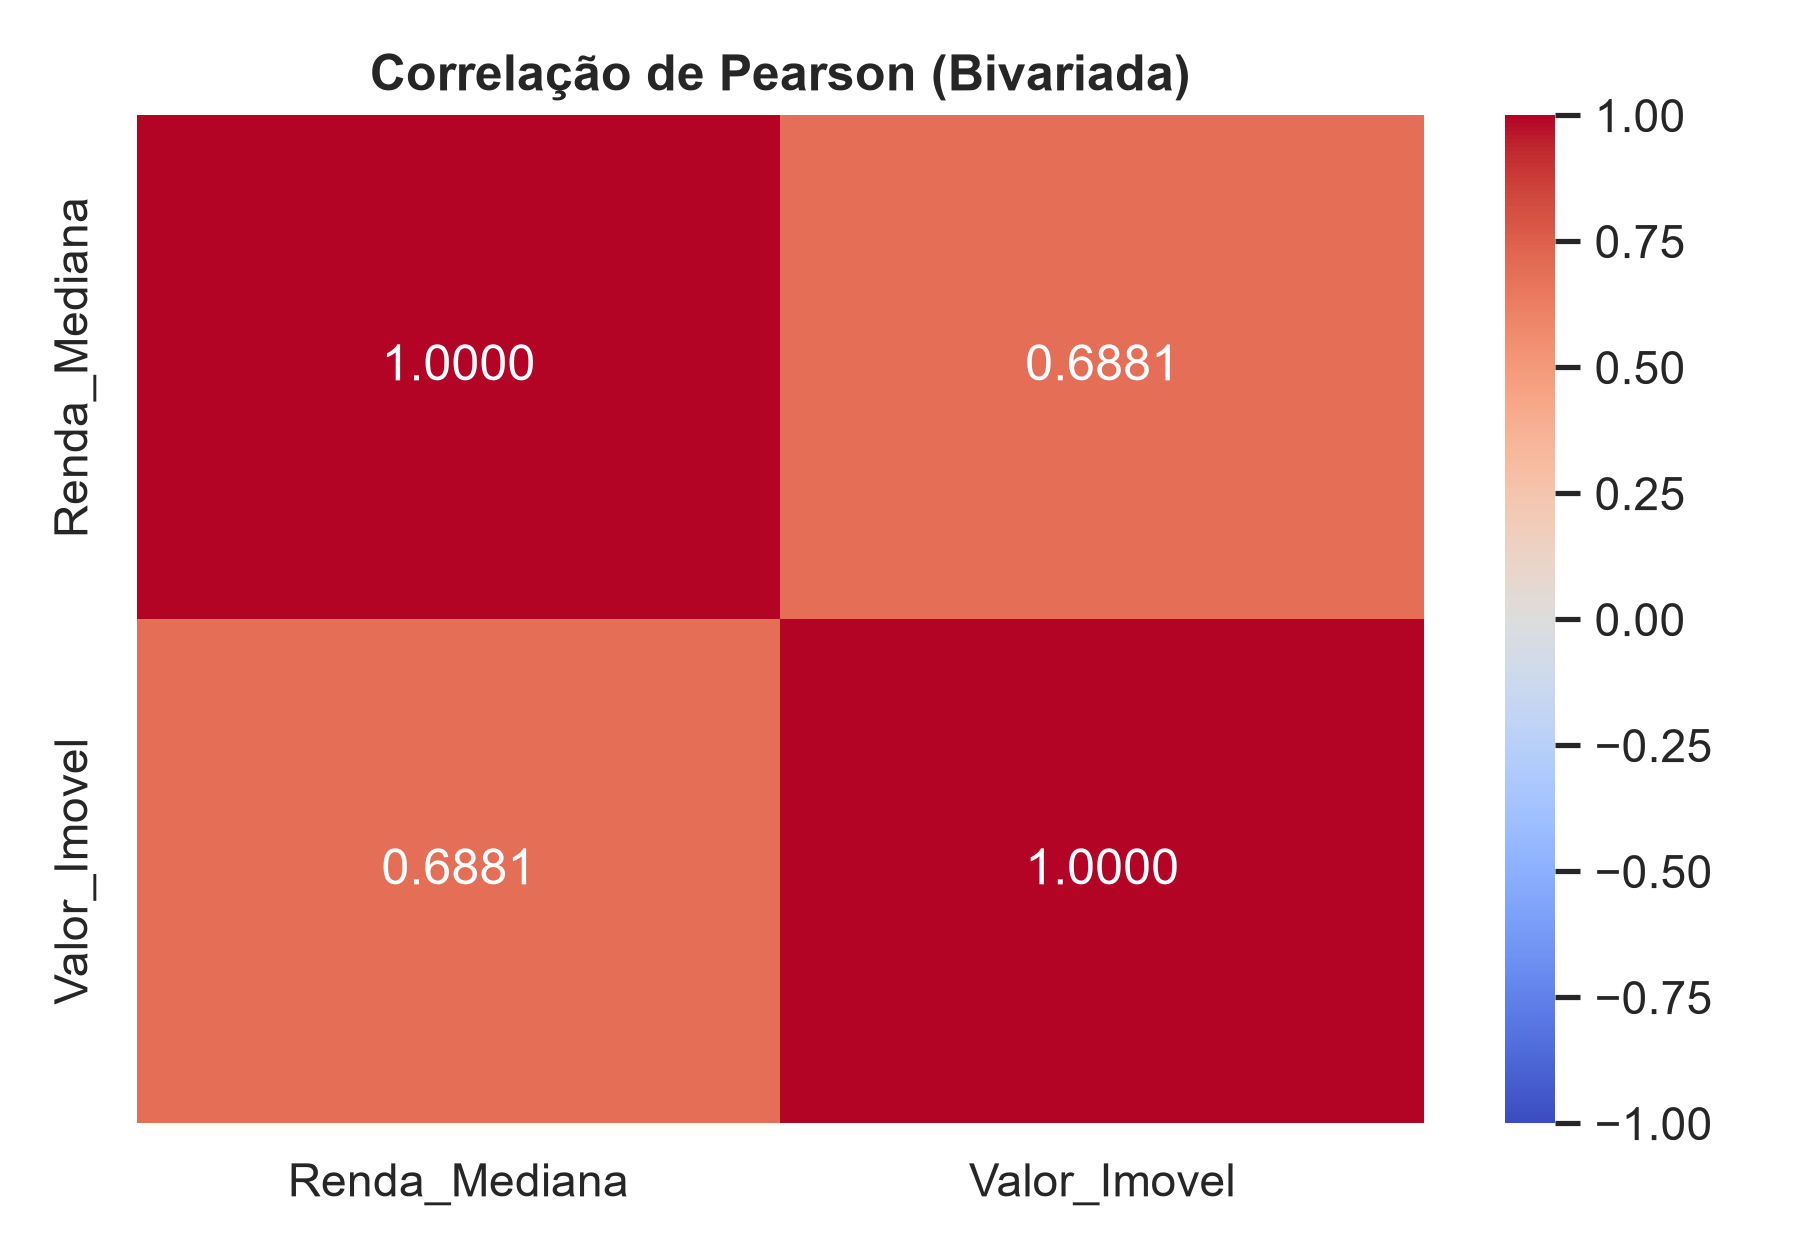

In [4]:
df_plot = df.sample(n=1500, random_state=42)

cov_xy = df["Renda_Mediana"].cov(df["Valor_Imovel"])
corr_xy, p_corr = stats.pearsonr(df["Renda_Mediana"], df["Valor_Imovel"])
print(f"b) Covariância: {cov_xy:,.4f}")
print(f"b) Correlação de Pearson (r): {corr_xy:.4f} (p-valor: {p_corr:.4e})")

X_biv = sm.add_constant(df["Renda_Mediana"])
modelo_biv = sm.OLS(df["Valor_Imovel"], X_biv).fit()
b0_b, b1_b = modelo_biv.params["const"], modelo_biv.params["Renda_Mediana"]

print(f"d) Equação: Valor_Imovel = {b0_b:.4f} + ({b1_b:.4f} * Renda_Mediana)")
print(f"e) R²: {modelo_biv.rsquared:.4f} | Teste F: {modelo_biv.fvalue:.4f} (p-valor F: {modelo_biv.f_pvalue:.4e})")

prev_biv = b0_b + (b1_b * 5.0)
print(f"f) Previsão para Renda_Mediana = 5.0 ($50k) -> Valor estimado = $ {prev_biv:,.2f}")


---
### 05) Análise Multivariada e Regressão Linear Múltipla
Incorporação das variáveis explicativas estruturais (`Idade_Imovel` e `Total_Comodos`) juntamente com `Renda_Mediana` para explicar e prever `Valor_Imovel`.


b) Matriz de Covariância:
                Renda_Mediana  Idade_Imovel  Total_Comodos  Valor_Imovel
Renda_Mediana         3.6093       -2.8461   8.208524e+02  1.508475e+05
Idade_Imovel         -2.8461      158.3963  -9.919120e+03  1.533988e+05
Total_Comodos       820.8524    -9919.1201   4.759445e+06  3.377289e+07
Valor_Imovel     150847.4828   153398.8013   3.377289e+07  1.331615e+10

b) Matriz de Correlação de Pearson:
                Renda_Mediana  Idade_Imovel  Total_Comodos  Valor_Imovel
Renda_Mediana         1.0000       -0.1190         0.1980        0.6881
Idade_Imovel         -0.1190        1.0000        -0.3613        0.1056
Total_Comodos         0.1980       -0.3613         1.0000        0.1342
Valor_Imovel          0.6881        0.1056         0.1342        1.0000

d) Equação: Valor_Imovel = -24329.8794 + (42467.0389*Renda) + (1974.9806*Idade) + (3.8878*Comodos)
e) R²: 0.5137 | R² Ajustado: 0.5136 | Teste F: 7265.8059 (p-valor F: 0.0000e+00)
f) Previsão (Renda=4.5, Idade=25, 

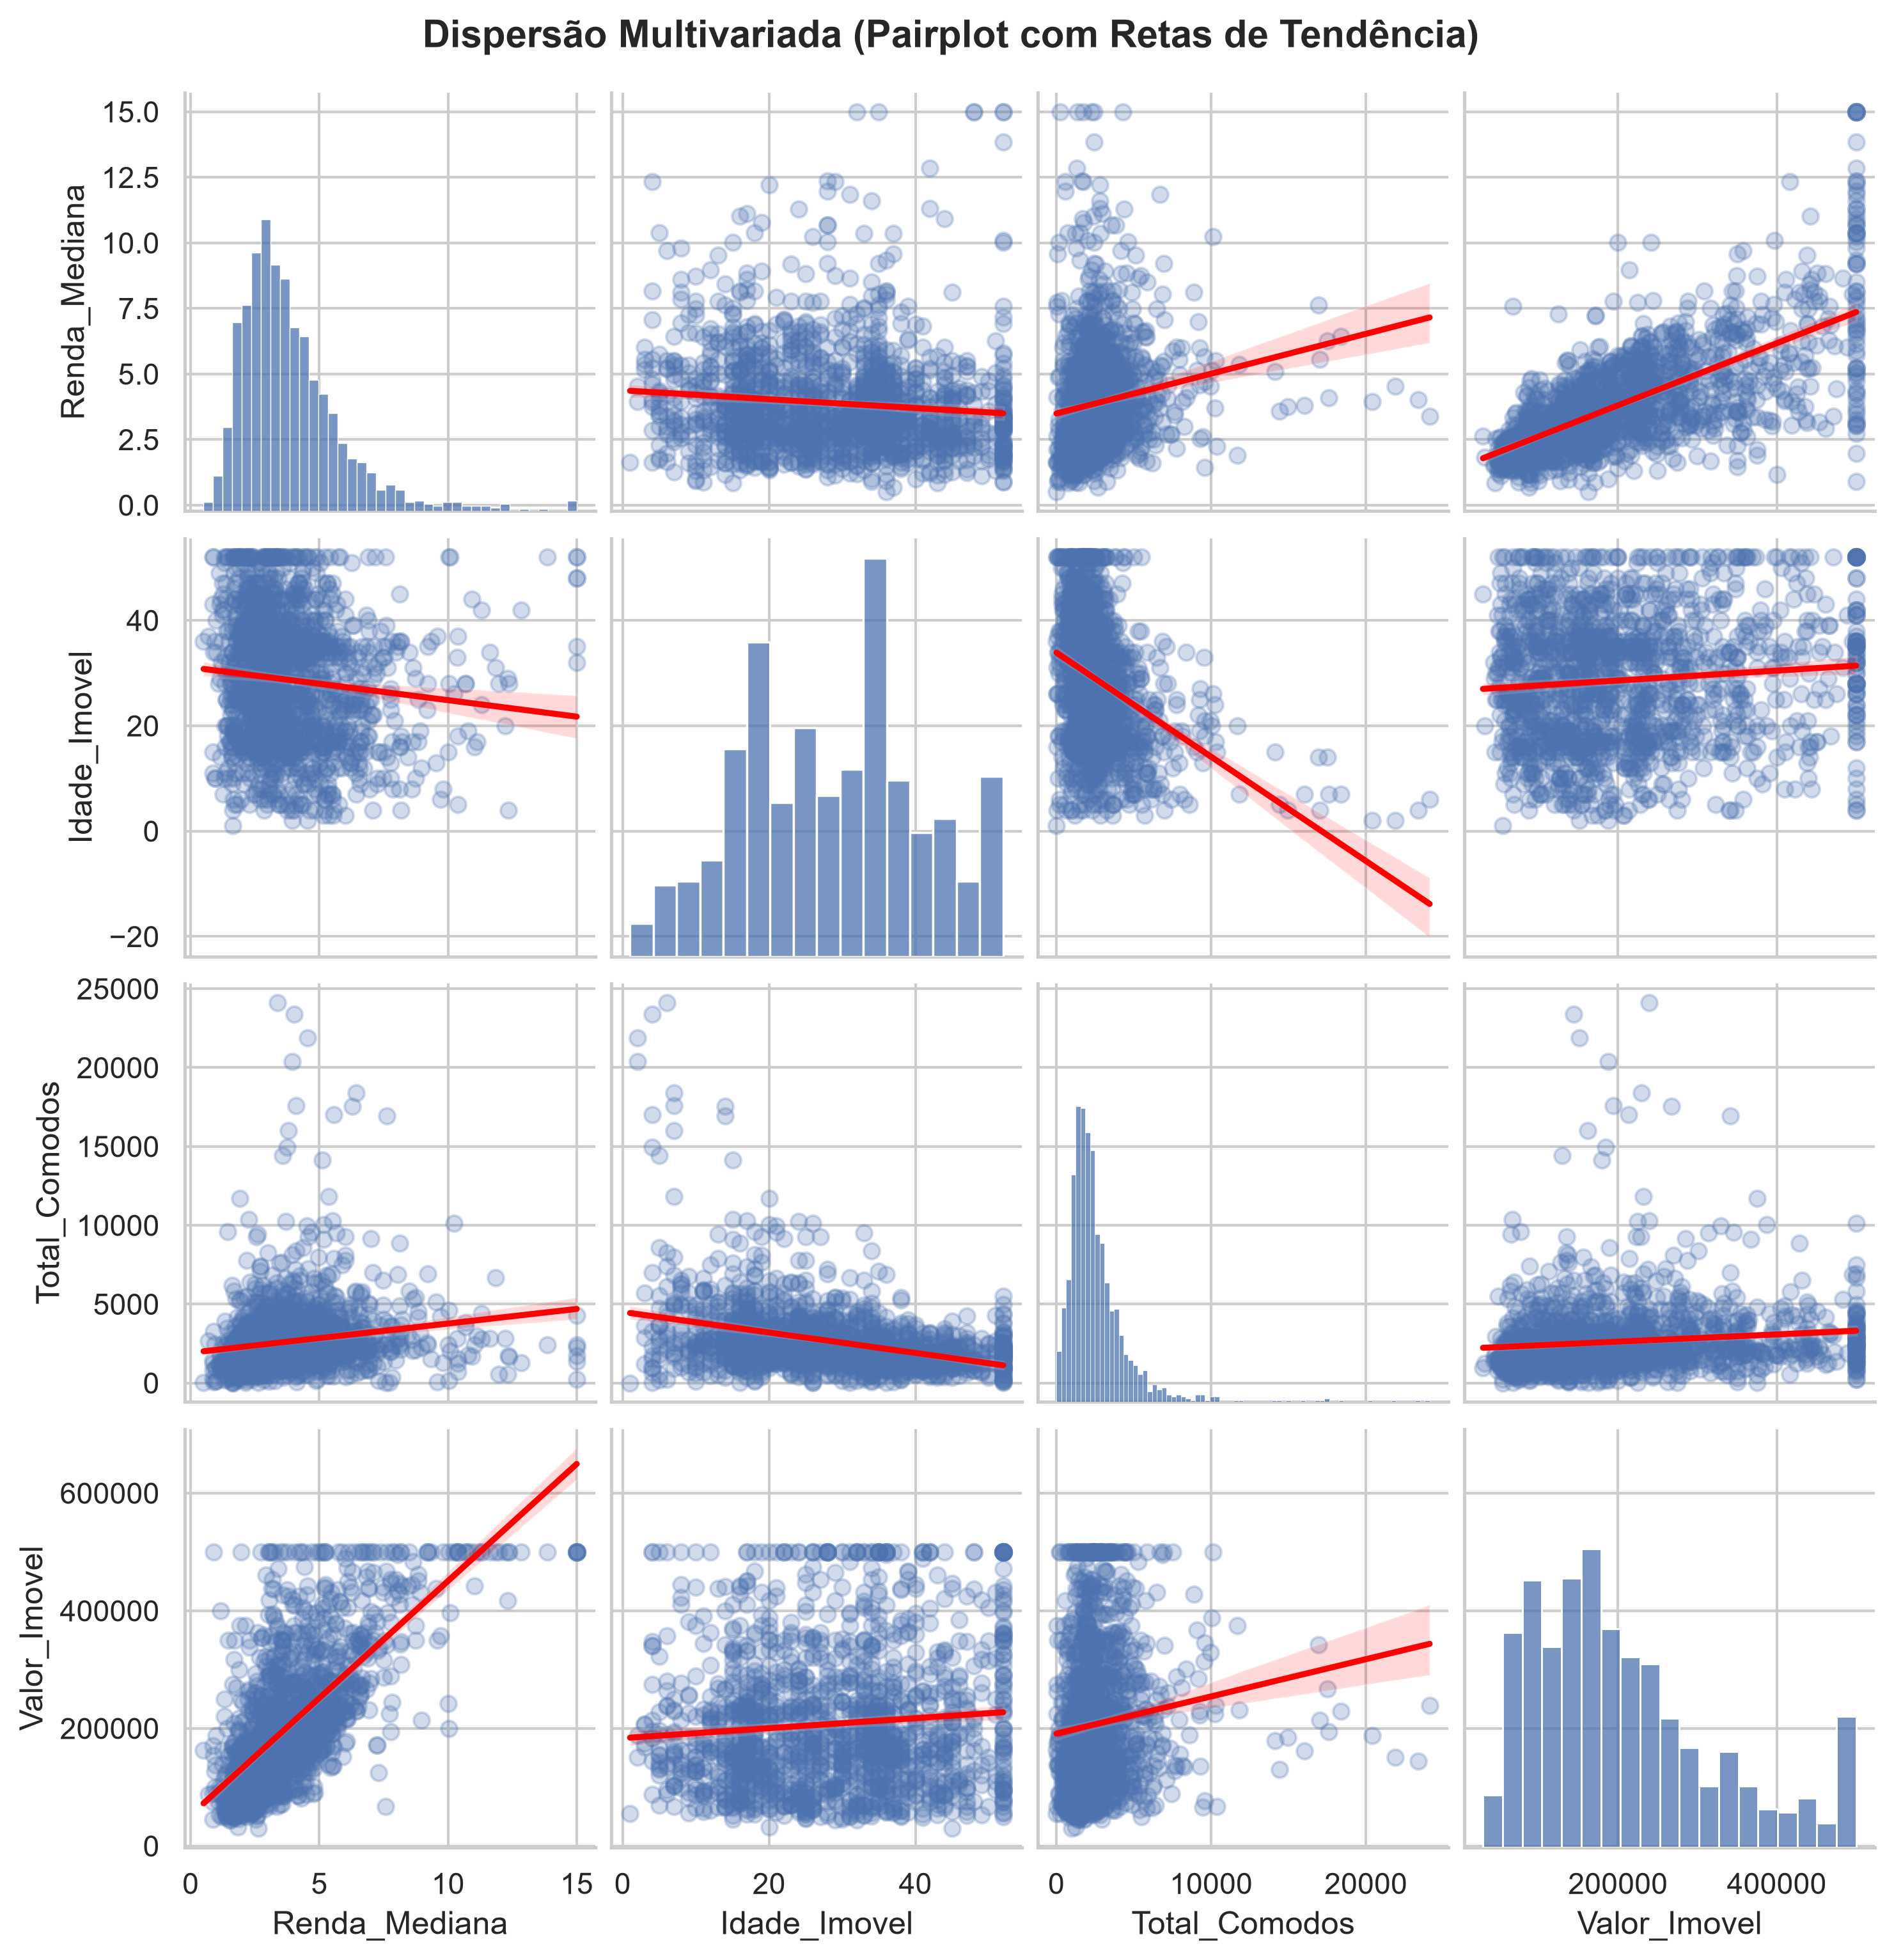

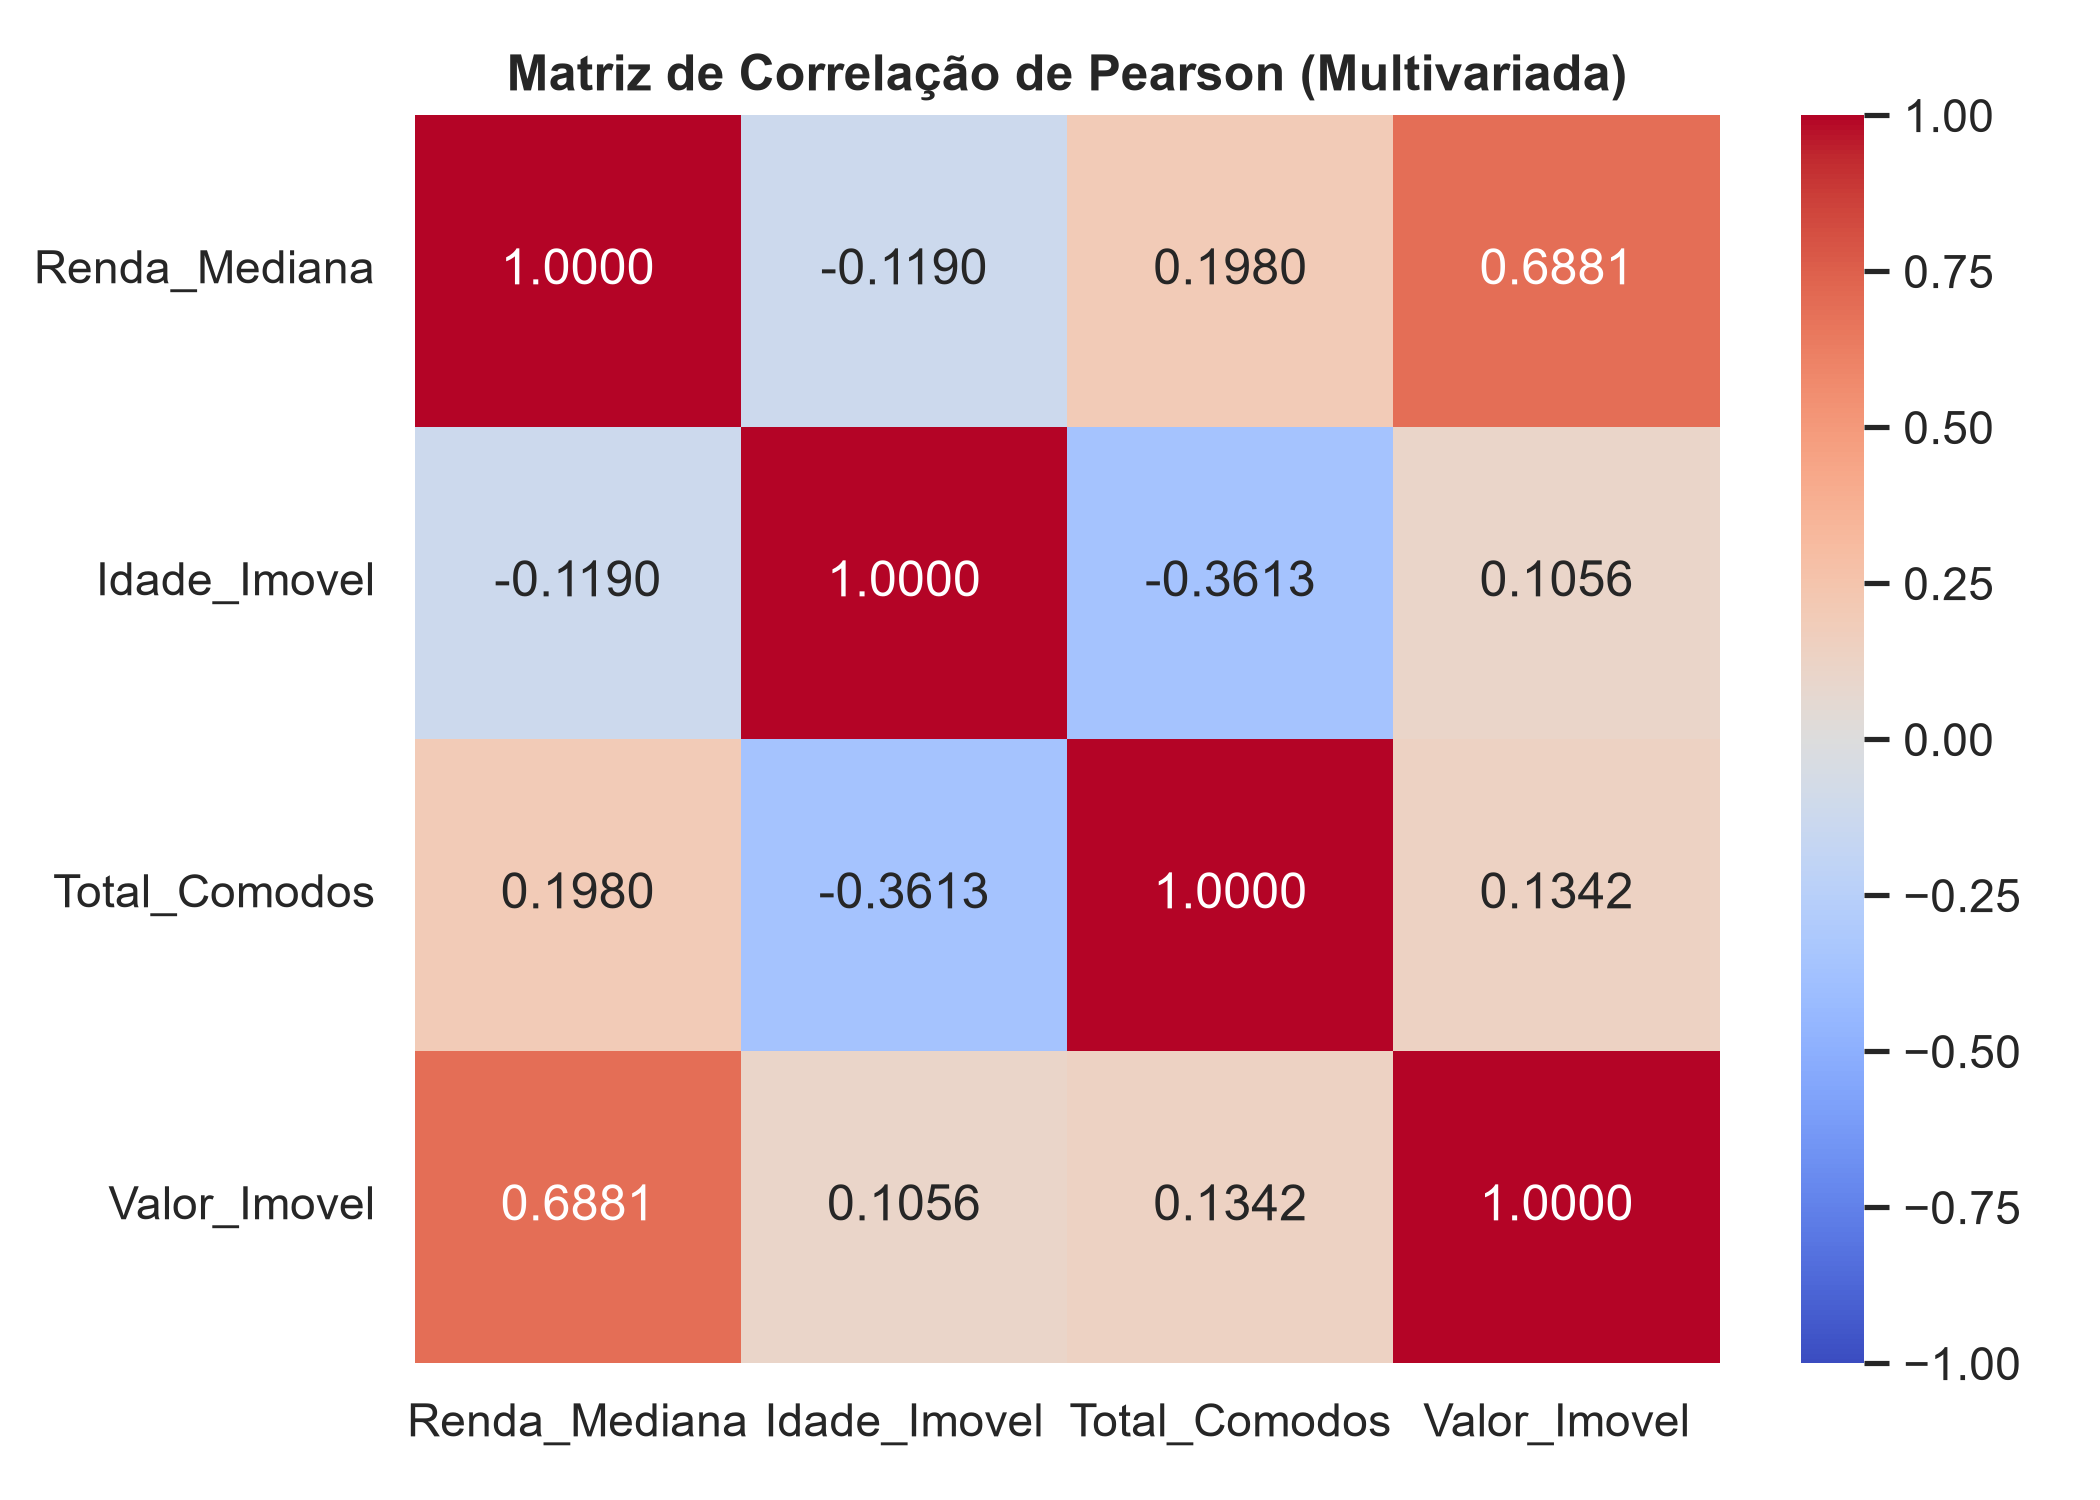

In [5]:
cols_m = ["Renda_Mediana", "Idade_Imovel", "Total_Comodos", "Valor_Imovel"]

print("b) Matriz de Covariância:\n", df[cols_m].cov().round(4))
print("\nb) Matriz de Correlação de Pearson:\n", df[cols_m].corr().round(4))

X_mult = sm.add_constant(df[["Renda_Mediana", "Idade_Imovel", "Total_Comodos"]])
modelo_mult = sm.OLS(df["Valor_Imovel"], X_mult).fit()
p = modelo_mult.params

print(f"\nd) Equação: Valor_Imovel = {p['const']:.4f} + ({p['Renda_Mediana']:.4f}*Renda) + ({p['Idade_Imovel']:.4f}*Idade) + ({p['Total_Comodos']:.4f}*Comodos)")
print(f"e) R²: {modelo_mult.rsquared:.4f} | R² Ajustado: {modelo_mult.rsquared_adj:.4f} | Teste F: {modelo_mult.fvalue:.4f} (p-valor F: {modelo_mult.f_pvalue:.4e})")

prev_mult = p["const"] + (p["Renda_Mediana"] * 4.5) + (p["Idade_Imovel"] * 25.0) + (p["Total_Comodos"] * 2500.0)
print(f"f) Previsão (Renda=4.5, Idade=25, Comodos=2500) -> Valor estimado = $ {prev_mult:,.2f}")


---
### 06) Regressão Logística Binária (Classificação de `Valor_Alto`)
Classificação probabilística para identificar se um setor censitário possui valor imobiliário acima da mediana ($> \text{US\$ } 179.700,00 \implies \text{Valor\_Alto} = 1$) ou acessível ($\le \text{US\$ } 179.700,00 \implies \text{Valor\_Alto} = 0$).


a) Equação Logit (z): z = -5.5847 + (1.1095*Renda) + (0.0441*Idade) + (0.000095*Comodos)
a) Probabilidade: P(Valor_Alto=1) = 1 / (1 + exp(-z))
b) Acurácia no conjunto de teste: 0.7642 (76.42%)
b) Matriz de Confusão:
 [[2443  654]
 [ 806 2289]]
c) Classificação (Renda=4.5, Idade=25, Comodos=2500): P(Valor_Alto=1) = 0.6787 -> Classe = 1


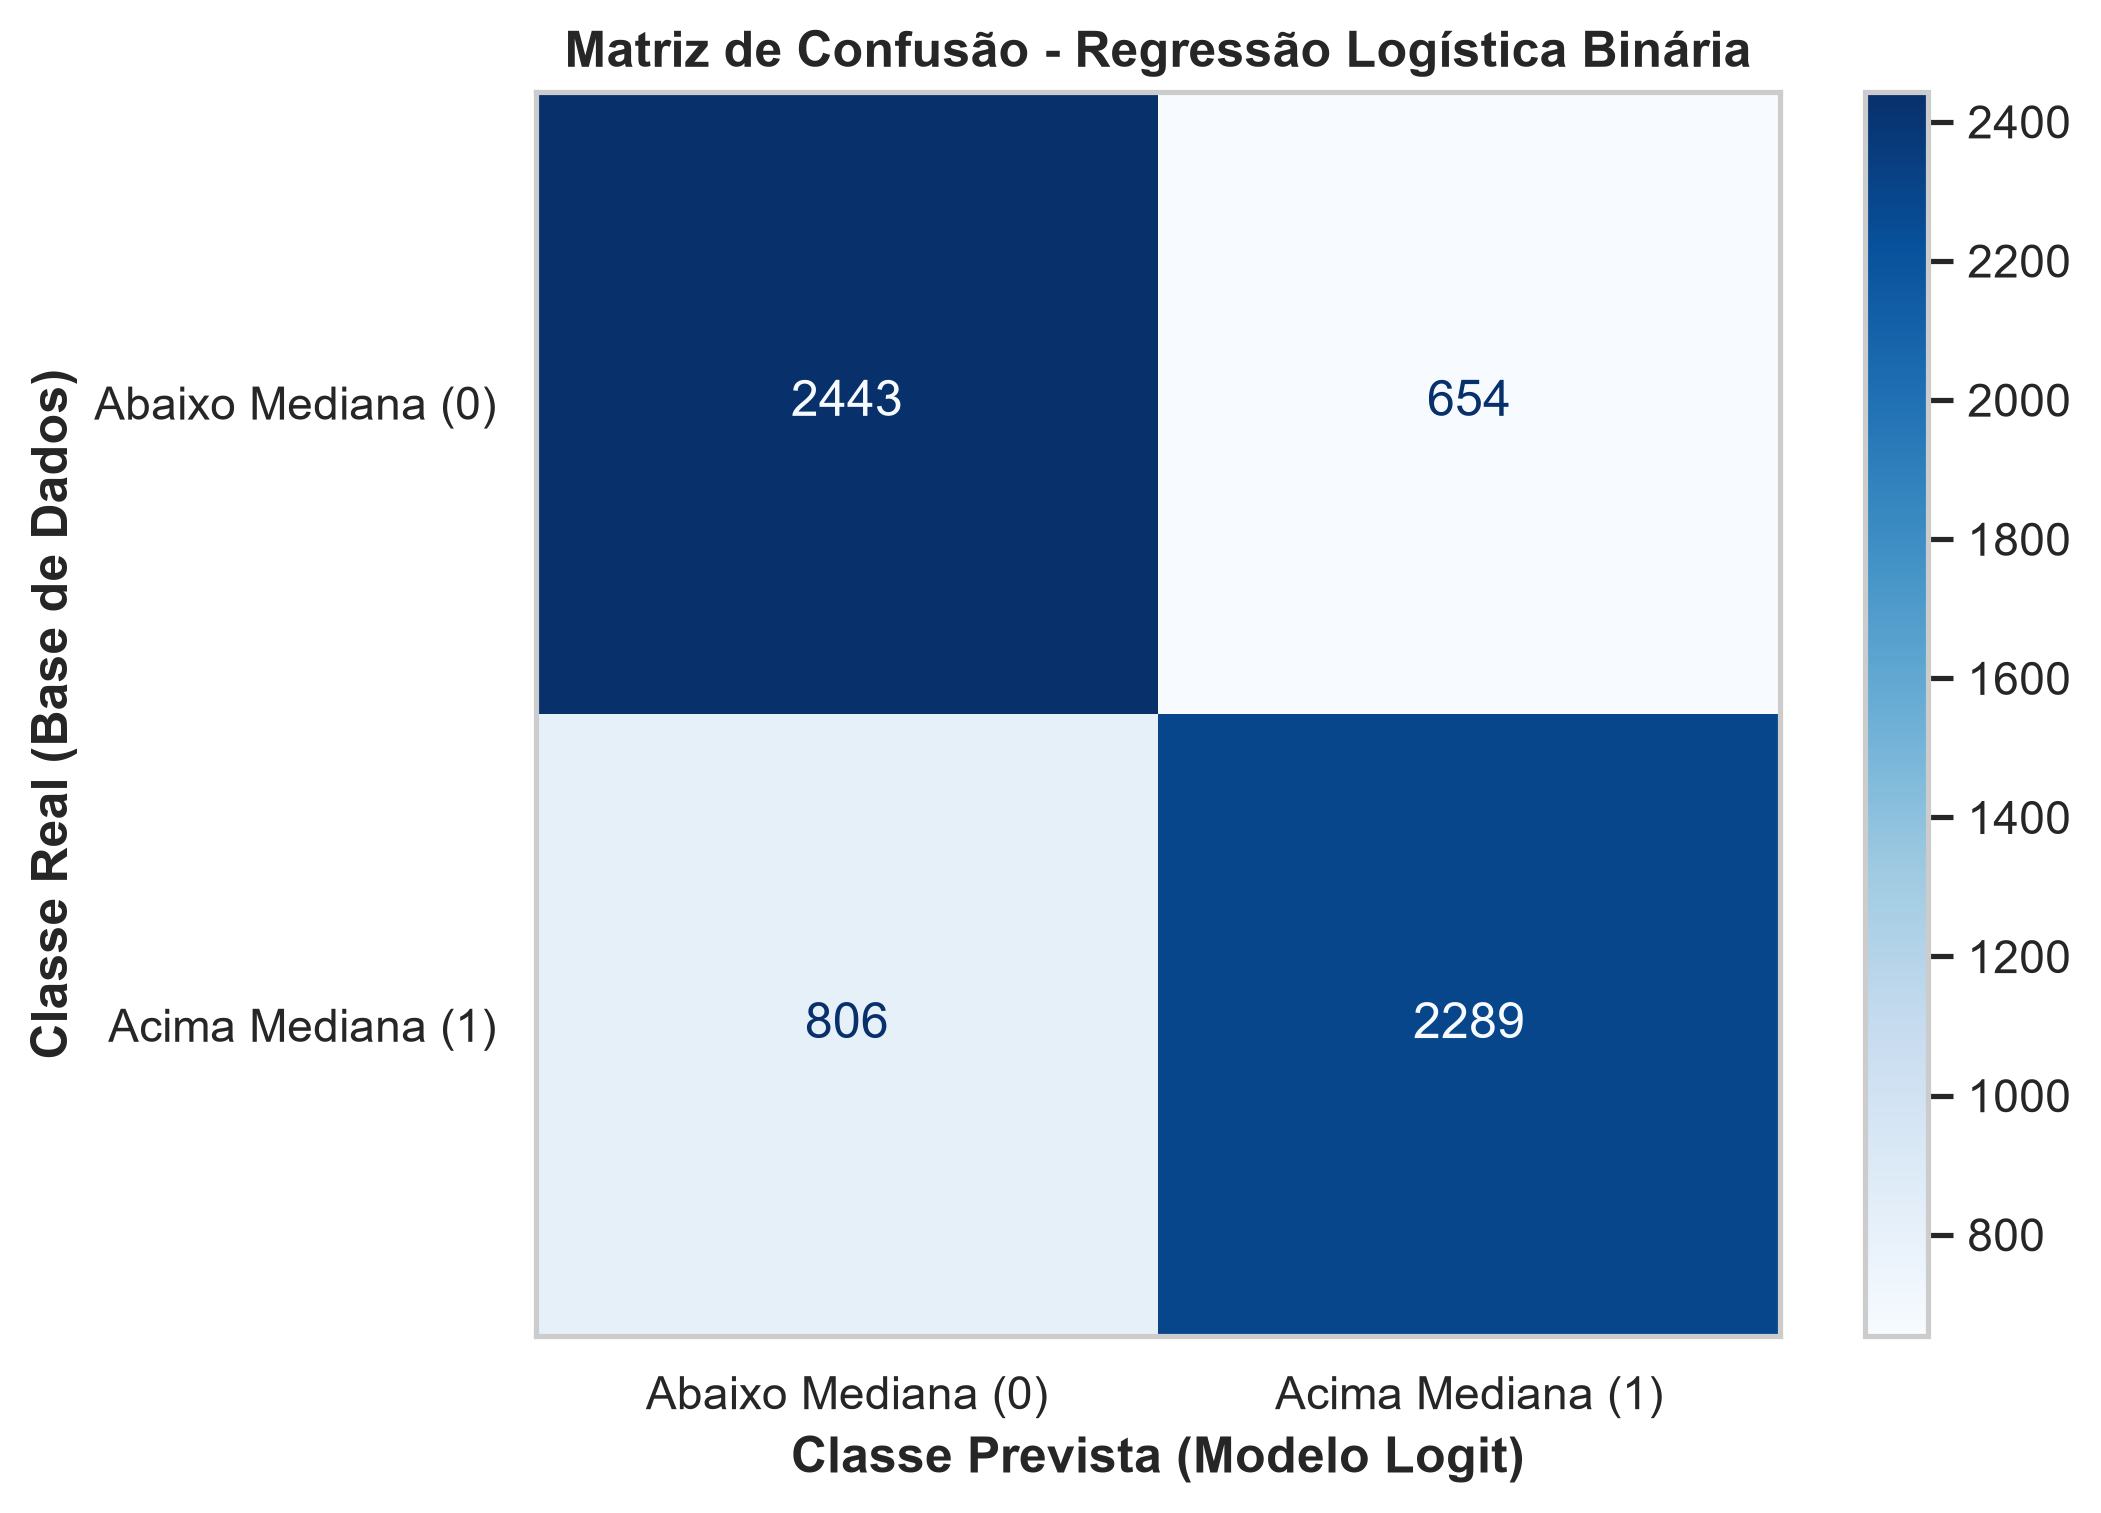

In [6]:
X_log = df[["Renda_Mediana", "Idade_Imovel", "Total_Comodos"]]
y_log = df["Valor_Alto"]

X_train, X_test, y_train, y_test = train_test_split(
    X_log, y_log, test_size=0.30, random_state=42, stratify=y_log
)

X_train_sm = sm.add_constant(X_train)
modelo_logit = sm.Logit(y_train, X_train_sm).fit(disp=False)
pl = modelo_logit.params

print(f"a) Equação Logit (z): z = {pl['const']:.4f} + ({pl['Renda_Mediana']:.4f}*Renda) + ({pl['Idade_Imovel']:.4f}*Idade) + ({pl['Total_Comodos']:.6f}*Comodos)")
print("a) Probabilidade: P(Valor_Alto=1) = 1 / (1 + exp(-z))")

X_test_sm = sm.add_constant(X_test)
y_pred = (modelo_logit.predict(X_test_sm) >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print(f"b) Acurácia no conjunto de teste: {acc:.4f} ({acc*100:.2f}%)")
print("b) Matriz de Confusão:\n", cm)

novo_caso = pd.DataFrame({
    "const": [1.0],
    "Renda_Mediana": [4.5],
    "Idade_Imovel": [25.0],
    "Total_Comodos": [2500.0],
})
prob_novo = modelo_logit.predict(novo_caso).iloc[0]
print(f"c) Classificação (Renda=4.5, Idade=25, Comodos=2500): P(Valor_Alto=1) = {prob_novo:.4f} -> Classe = {int(prob_novo >= 0.5)}")
